# **KẾT NỐI VÀ KIỂM TRA DỮ LIỆU**

In [1]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import time

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
OPCODE_PATH = Path(
    "/content/drive/MyDrive/IS6002/EXPERIMENT/implementation/data/raw/opcode_by_contract.csv"
)

df = pd.read_csv(OPCODE_PATH)

print("========== DATASET ==========")
print("Số hợp đồng:", len(df))
print("Số cột:", len(df.columns))

print("\nDanh sách cột đầu tiên:")
print(df.columns[:15].tolist())

print("\nPhân bố nhãn:")
print(df["label"].value_counts(dropna=False))

print("\nSố giá trị thiếu:")
print(df.isna().sum().sum())

print("\nSố contract_id trùng:")
print(df["contract_id"].duplicated().sum())

========== DATASET ==========
Số hợp đồng: 39905
Số cột: 258

Danh sách cột đầu tiên:
['contract_id', 'ADD', 'ADDMOD', 'ADDRESS', 'AND', 'BALANCE', 'BLOCKHASH', 'BYTE', 'CALL', 'CALLCODE', 'CALLDATACOPY', 'CALLDATALOAD', 'CALLDATASIZE', 'CALLER', 'CALLVALUE']

Phân bố nhãn:
label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64

Số giá trị thiếu:
0

Số contract_id trùng:
0


# **EDA**

In [3]:
opcode_cols = [
    col for col in df.columns
    if col not in ["contract_id", "label"]
]

X_raw = df[opcode_cols].apply(pd.to_numeric, errors="coerce")

print("========== 1. TỔNG QUAN DATASET ==========")
print(f"Tổng số Smart Contract: {len(df):,}")
print(f"Số đặc trưng Opcode: {len(opcode_cols):,}")
print(f"Tổng số cột: {len(df.columns):,}")

print("\n========== 2. PHÂN BỐ NHÃN ==========")
print(df["label"].value_counts(dropna=False))

print("\nTỷ lệ (%):")
print(
    df["label"].value_counts(
        normalize=True, dropna=False
    ).mul(100).round(2)
)

print("\n========== 3. CHẤT LƯỢNG DỮ LIỆU ==========")
print("Contract ID trùng:", df["contract_id"].duplicated().sum())
print("Giá trị thiếu:", X_raw.isna().sum().sum())
print("Giá trị âm:", (X_raw < 0).sum().sum())
print("Đặc trưng toàn 0:", (X_raw.fillna(0).sum(axis=0) == 0).sum())
print(
    "Hợp đồng không có Opcode:",
    (X_raw.fillna(0).sum(axis=1) == 0).sum()
)

========== 1. TỔNG QUAN DATASET ==========
Tổng số Smart Contract: 39,905
Số đặc trưng Opcode: 256
Tổng số cột: 258

========== 2. PHÂN BỐ NHÃN ==========
label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64

Tỷ lệ (%):
label
Vulnerable        70.29
Non-vulnerable    29.71
Name: proportion, dtype: float64

========== 3. CHẤT LƯỢNG DỮ LIỆU ==========
Contract ID trùng: 0
Giá trị thiếu: 0
Giá trị âm: 0
Đặc trưng toàn 0: 0
Hợp đồng không có Opcode: 0


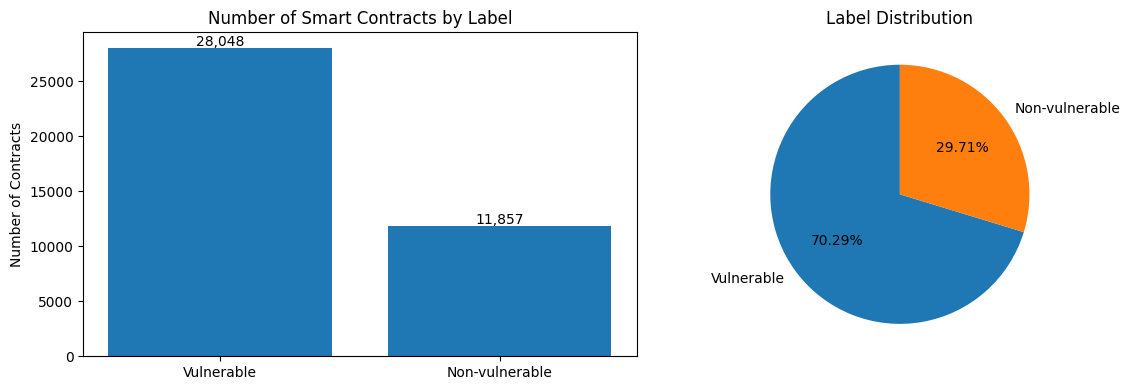

In [4]:
import matplotlib.pyplot as plt

label_counts = df["label"].value_counts()
label_percent = df["label"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(label_counts.index, label_counts.values)
axes[0].set_title("Number of Smart Contracts by Label")
axes[0].set_ylabel("Number of Contracts")

for i, value in enumerate(label_counts.values):
    axes[0].text(i, value + 200, f"{value:,}", ha="center")

axes[1].pie(
    label_counts.values,
    labels=label_counts.index,
    autopct="%1.2f%%",
    startangle=90
)
axes[1].set_title("Label Distribution")

plt.tight_layout()
plt.show()

========== THỐNG KÊ TỔNG OPCODE THEO NHÃN ==========
                count     mean  median      std  min     max
label                                                       
Non-vulnerable  11857  3902.46  3362.0  3029.55    6   31638
Vulnerable      28048  6995.52  4656.0  7681.78   21  148591


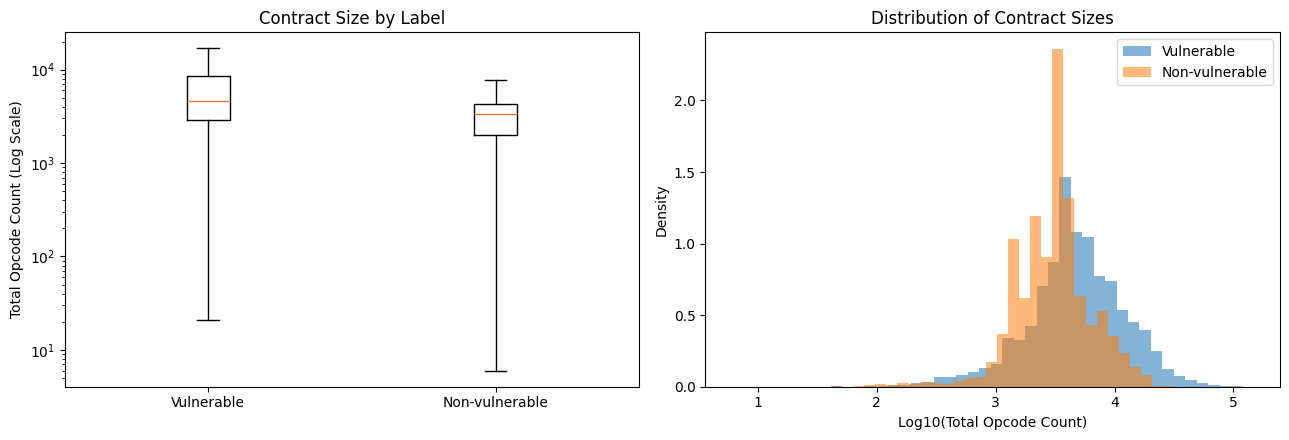

In [5]:
total_opcode = X_raw.sum(axis=1)

eda_size = pd.DataFrame({
    "label": df["label"],
    "total_opcode": total_opcode
})

print("========== THỐNG KÊ TỔNG OPCODE THEO NHÃN ==========")

stats = eda_size.groupby("label")["total_opcode"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(stats.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

groups = [
    eda_size.loc[
        eda_size["label"] == label, "total_opcode"
    ].values
    for label in ["Vulnerable", "Non-vulnerable"]
]

axes[0].boxplot(
    groups,
    tick_labels=["Vulnerable", "Non-vulnerable"],
    showfliers=False
)
axes[0].set_yscale("log")
axes[0].set_title("Contract Size by Label")
axes[0].set_ylabel("Total Opcode Count (Log Scale)")

for label in ["Vulnerable", "Non-vulnerable"]:
    values = eda_size.loc[
        eda_size["label"] == label, "total_opcode"
    ]
    axes[1].hist(
        np.log10(values),
        bins=40,
        alpha=0.55,
        density=True,
        label=label
    )

axes[1].set_title("Distribution of Contract Sizes")
axes[1].set_xlabel("Log10(Total Opcode Count)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

========== TỔNG QUAN OPCODE ==========
Số đặc trưng: 256
Opcode xuất hiện ở mọi hợp đồng: 2
Opcode xuất hiện trong dưới 1% hợp đồng: 134

========== TOP 15 OPCODE PHỔ BIẾN ==========
          total_count  contracts_present  presence_pct
PUSH1        33590182              39905        100.00
SWAP1        18459496              39900         99.99
POP          16981194              39895         99.97
DUP1         16827055              39904        100.00
PUSH2        13237636              39839         99.83
DUP2         13048360              39875         99.92
ADD          12347573              39818         99.78
JUMPDEST     10542382              39903         99.99
AND          10434935              39895         99.97
ISZERO        8470463              39901         99.99
MSTORE        8045067              39905        100.00
PUSH20        7986981              39793         99.72
SWAP2         7019444              39808         99.76
JUMPI         5924144              39902       

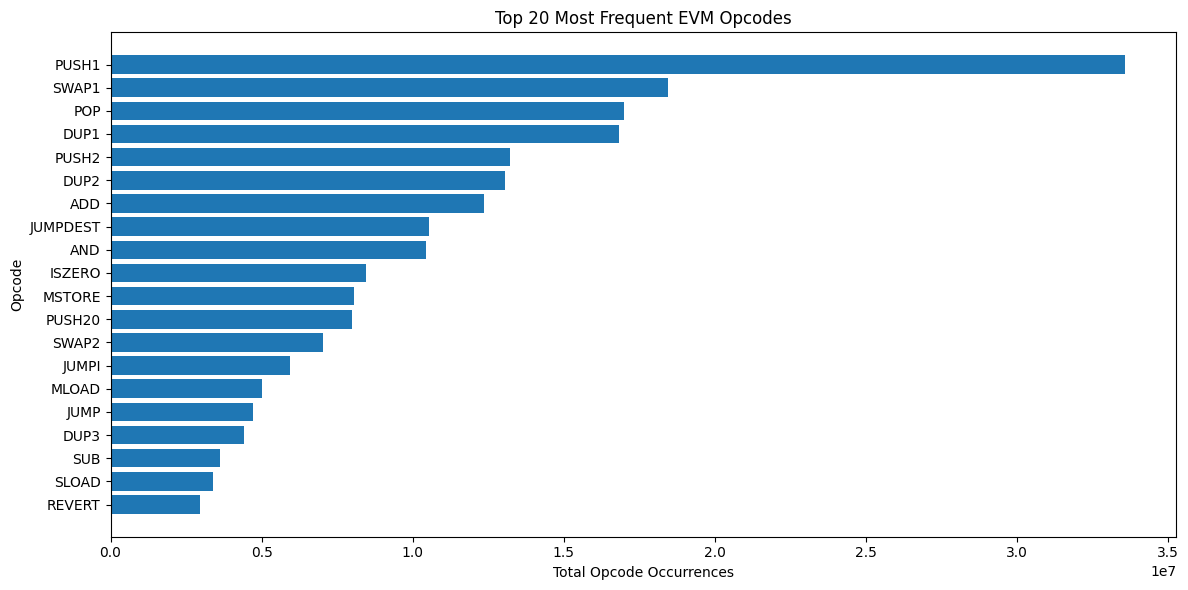

In [6]:
opcode_stats = pd.DataFrame({
    "total_count": X_raw.sum(axis=0),
    "contracts_present": (X_raw > 0).sum(axis=0),
    "mean": X_raw.mean(axis=0),
    "std": X_raw.std(axis=0)
})

opcode_stats["presence_pct"] = (
    opcode_stats["contracts_present"] / len(X_raw) * 100
)

opcode_stats = opcode_stats.sort_values(
    "total_count", ascending=False
)

print("========== TỔNG QUAN OPCODE ==========")
print("Số đặc trưng:", len(opcode_stats))
print("Opcode xuất hiện ở mọi hợp đồng:",
      (opcode_stats["presence_pct"] == 100).sum())
print("Opcode xuất hiện trong dưới 1% hợp đồng:",
      (opcode_stats["presence_pct"] < 1).sum())

print("\n========== TOP 15 OPCODE PHỔ BIẾN ==========")
print(
    opcode_stats[
        ["total_count", "contracts_present", "presence_pct"]
    ].head(15).round(2).to_string()
)

print("\n========== TOP 15 OPCODE ÍT PHỔ BIẾN ==========")
print(
    opcode_stats[
        ["total_count", "contracts_present", "presence_pct"]
    ].tail(15).round(2).to_string()
)

sparsity = (X_raw == 0).to_numpy().mean() * 100

print("\n========== SPARSITY ==========")
print(f"Tỷ lệ giá trị bằng 0: {sparsity:.2f}%")

top20 = opcode_stats.head(20)

plt.figure(figsize=(12, 6))
plt.barh(
    top20.index[::-1],
    top20["total_count"].values[::-1]
)

plt.title("Top 20 Most Frequent EVM Opcodes")
plt.xlabel("Total Opcode Occurrences")
plt.ylabel("Opcode")
plt.tight_layout()
plt.show()

# **DATA SPLITTING**

Chia dữ liệu **trước** khi chuẩn hóa.

Bước chuẩn hóa của Autoencoder dùng `MinMaxScaler` theo cột, mà phép này lấy min/max của
mỗi cột **trên nhiều hợp đồng**. Nếu fit trước khi chia thì thông tin của Validation/Test
rò rỉ vào phép chuẩn hóa. Scaler vì vậy chỉ được `fit` trên tập Train.

Chia 70/15/15, `stratify` theo nhãn, `random_state=42`.

In [7]:
from sklearn.model_selection import train_test_split
import hashlib

RANDOM_STATE = 42

assert df["contract_id"].is_unique, "contract_id trùng"
assert set(df["label"].unique()) == {"Non-vulnerable", "Vulnerable"}
assert X_raw.shape[1] == 256, f"Dự kiến 256 Opcode, thấy {X_raw.shape[1]}"
assert X_raw.notna().all().all(), "Opcode có NaN"
assert np.isfinite(X_raw.to_numpy()).all(), "Opcode không hữu hạn"
assert (X_raw >= 0).all().all(), "Opcode có giá trị âm"
assert (X_raw.sum(axis=1) > 0).all(), "Có hợp đồng không chứa Opcode"

y = df["label"].copy()

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("========== DATA SPLIT ==========")

for name, Xs, labels in [
    ("Train", X_train_raw, y_train),
    ("Validation", X_val_raw, y_val),
    ("Test", X_test_raw, y_test)
]:
    print(f"\n{name}")
    print("Số hợp đồng:", f"{len(Xs):,}")
    print("Kích thước:", Xs.shape)
    print("Tỷ lệ nhãn (%):")
    print(
        labels.value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

assert set(X_train_raw.index).isdisjoint(X_val_raw.index)
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
assert set(X_val_raw.index).isdisjoint(X_test_raw.index)
assert len(X_train_raw) + len(X_val_raw) + len(X_test_raw) == len(df)

print("\nChia dữ liệu thành công, không trùng hợp đồng giữa các tập.")


def index_checksum(idx):
    arr = np.sort(np.asarray(idx)).tobytes()
    return hashlib.md5(arr).hexdigest()[:12]


print("\n========== SPLIT CHECKSUM ==========")
for name, idx in [("Train", X_train_raw.index),
                  ("Val", X_val_raw.index),
                  ("Test", X_test_raw.index)]:
    print(f"{name:6s}: {index_checksum(idx)}")

print("\nChecksum dùng để xác minh split khi chạy lại notebook.")

========== DATA SPLIT ==========

Train
Số hợp đồng: 27,933
Kích thước: (27933, 256)
Tỷ lệ nhãn (%):
label
Vulnerable        70.29
Non-vulnerable    29.71
Name: proportion, dtype: float64

Validation
Số hợp đồng: 5,986
Kích thước: (5986, 256)
Tỷ lệ nhãn (%):
label
Vulnerable        70.3
Non-vulnerable    29.7
Name: proportion, dtype: float64

Test
Số hợp đồng: 5,986
Kích thước: (5986, 256)
Tỷ lệ nhãn (%):
label
Vulnerable        70.28
Non-vulnerable    29.72
Name: proportion, dtype: float64

Chia dữ liệu thành công, không trùng hợp đồng giữa các tập.

========== SPLIT CHECKSUM ==========
Train : 1dfdf90d57f9
Val   : 972712eb42da
Test  : 691c33c23acc

Checksum dùng để xác minh split khi chạy lại notebook.


# **DATA PREPROCESSING**

`log1p` rồi `MinMaxScaler` theo từng cột Opcode, scaler `fit` chỉ trên tập Train.

Hai lý do chọn cách này:

- Tầng đầu ra của Autoencoder là `sigmoid`, nên dữ liệu đầu vào phải nằm trong [0, 1].
- Cơ chế phát hiện bất thường cần **giữ lại độ lớn** của hợp đồng: chỉ khi hợp đồng nằm
  ngoài vùng phân phối mà mô hình học từ lớp Non-vulnerable thì reconstruction error
  mới cao.

Giá trị của Validation/Test vượt khoảng của Train được `clip` về [0, 1] để khớp với
thang đo mà mô hình đã học.

In [8]:
from sklearn.preprocessing import MinMaxScaler

LABEL_NORMAL = "Non-vulnerable"
LABEL_VULNERABLE = "Vulnerable"

X_train_log = np.log1p(X_train_raw.to_numpy(dtype="float64"))
X_val_log = np.log1p(X_val_raw.to_numpy(dtype="float64"))
X_test_log = np.log1p(X_test_raw.to_numpy(dtype="float64"))

# MinMaxScaler chỉ fit trên Train
scaler = MinMaxScaler()
scaler.fit(X_train_log)

X_train_s = scaler.transform(X_train_log)
X_val_s = scaler.transform(X_val_log)
X_test_s = scaler.transform(X_test_log)

n_out_val = int(((X_val_s < 0) | (X_val_s > 1)).sum())
n_out_test = int(((X_test_s < 0) | (X_test_s > 1)).sum())

X_train = np.clip(X_train_s, 0.0, 1.0).astype(np.float32)
X_val = np.clip(X_val_s, 0.0, 1.0).astype(np.float32)
X_test = np.clip(X_test_s, 0.0, 1.0).astype(np.float32)

# Nhãn dạng số: 1 = Vulnerable, 0 = Non-vulnerable
y_train_bin = (y_train.to_numpy() == LABEL_VULNERABLE).astype(int)
y_val_bin = (y_val.to_numpy() == LABEL_VULNERABLE).astype(int)
y_test_bin = (y_test.to_numpy() == LABEL_VULNERABLE).astype(int)

# Autoencoder chỉ học lớp Non-vulnerable
X_train_normal = X_train[y_train_bin == 0]
X_train_vulnerable = X_train[y_train_bin == 1]
X_val_normal = X_val[y_val_bin == 0]

for name, arr in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    assert np.isfinite(arr).all(), f"{name}: có NaN hoặc Inf"
    assert (arr >= 0).all() and (arr <= 1).all(), f"{name}: giá trị ngoài [0, 1]"

assert len(X_train) == len(y_train_bin)
assert len(X_val) == len(y_val_bin)
assert len(X_test) == len(y_test_bin)

print("========== LOG1P + MINMAX SCALER (fit trên Train) ==========")
print("Train     :", X_train.shape,
      f"| min {X_train.min():.4f} | max {X_train.max():.4f}")
print("Validation:", X_val.shape,
      f"| min {X_val.min():.4f} | max {X_val.max():.4f}")
print("Test      :", X_test.shape, "(chưa đánh giá)")

print("\n========== GIÁ TRỊ VƯỢT KHOẢNG TRAIN (đã clip) ==========")
print(f"Validation: {n_out_val:,} / {X_val_s.size:,} "
      f"({n_out_val / X_val_s.size * 100:.4f}%)")
print(f"Test      : {n_out_test:,} / {X_test_s.size:,} "
      f"({n_out_test / X_test_s.size * 100:.4f}%)")

print("\n========== TẬP HUẤN LUYỆN AUTOENCODER ==========")
print("Non-vulnerable Train (nạp vào model):", X_train_normal.shape)
print("Vulnerable Train (chỉ để chẩn đoán) :", X_train_vulnerable.shape)
print("Non-vulnerable Validation (theo dõi loss):", X_val_normal.shape)

print("\nMinMaxScaler chỉ fit trên Train; Validation và Test chỉ được transform.")

========== LOG1P + MINMAX SCALER (fit trên Train) ==========
Train     : (27933, 256) | min 0.0000 | max 1.0000
Validation: (5986, 256) | min 0.0000 | max 1.0000
Test      : (5986, 256) (chưa đánh giá)

========== GIÁ TRỊ VƯỢT KHOẢNG TRAIN (đã clip) ==========
Validation: 23 / 1,532,416 (0.0015%)
Test      : 36 / 1,532,416 (0.0023%)

========== TẬP HUẤN LUYỆN AUTOENCODER ==========
Non-vulnerable Train (nạp vào model): (8300, 256)
Vulnerable Train (chỉ để chẩn đoán) : (19633, 256)
Non-vulnerable Validation (theo dõi loss): (1778, 256)

MinMaxScaler chỉ fit trên Train; Validation và Test chỉ được transform.


# **TRAINING**

**Kiến trúc:**

```
Encoder:  256 -> 192 -> 128 -> 64     (tanh)
Decoder:   64 -> 128 -> 192 -> 256    (tanh, lớp cuối sigmoid)
```

| Tham số | Giá trị |
|---|---|
| Loss | MSE |
| Optimizer | Adam, lr = 1e-3 |
| Batch size | 128 |
| Epoch tối đa | 150 |
| EarlyStopping | `val_loss`, patience 10, restore best weights |

Autoencoder chỉ học trên hợp đồng **Non-vulnerable** của tập Train. `EarlyStopping` theo dõi
loss trên **phần Non-vulnerable của Validation**, nên không nhãn Vulnerable nào tham gia
vào việc cập nhật trọng số hay chọn epoch.

**Quy tắc cố định trước khi chạy:** reconstruction error càng **cao** thì càng có khả năng
là `Vulnerable`. Nếu phân bố ngược chiều, chỉ báo cáo vấn đề, **không tự đảo dấu điểm số**
để đạt AUC cao hơn.

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import random

BATCH_SIZE = 128
MAX_EPOCHS = 150
PATIENCE = 10
LEARNING_RATE = 1e-3
LATENT_DIM = 64

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
keras.utils.set_random_seed(RANDOM_STATE)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

inputs = keras.Input(shape=(len(opcode_cols),), name="opcode_input")
x = layers.Dense(192, activation="tanh", name="encoder_192")(inputs)
x = layers.Dense(128, activation="tanh", name="encoder_128")(x)
z = layers.Dense(LATENT_DIM, activation="tanh", name="latent_64")(x)
x = layers.Dense(128, activation="tanh", name="decoder_128")(z)
x = layers.Dense(192, activation="tanh", name="decoder_192")(x)
outputs = layers.Dense(len(opcode_cols), activation="sigmoid", name="reconstruction")(x)

autoencoder = keras.Model(inputs, outputs, name="autoencoder")
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

print("========== AUTOENCODER CONFIGURATION ==========")
print("TensorFlow:", tf.__version__)
print("Input dim:", len(opcode_cols))
print("Latent dim:", LATENT_DIM)
print("Batch size:", BATCH_SIZE)
print("Max epochs:", MAX_EPOCHS)
print("EarlyStopping patience:", PATIENCE)
print("Loss: MSE | Optimizer: Adam", LEARNING_RATE)
print("Trainable parameters:", f"{autoencoder.count_params():,}")

autoencoder.summary()

========== AUTOENCODER CONFIGURATION ==========
TensorFlow: 2.21.0
Input dim: 256
Latent dim: 64
Batch size: 128
Max epochs: 150
EarlyStopping patience: 10
Loss: MSE | Optimizer: Adam 0.001
Trainable parameters: 164,800


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ opcode_input (InputLayer)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_192 (Dense)             │ (None, 192)            │        49,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_128 (Dense)             │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_64 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_128 (Dense)             │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_192 (Dense)             │ (None, 192)            │        24,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 256)            │        49,408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,800 (643.75 KB)

 Trainable params: 164,800 (643.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0257 - val_loss: 0.0030
Epoch 2/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0030 - val_loss: 0.0030
Epoch 3/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0029 - val_loss: 0.0029
Epoch 4/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0025 - val_loss: 0.0017
Epoch 5/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0014 - val_loss: 0.0013
Epoch 6/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 7/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 8/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 9/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 10/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 11/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 12/150
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step

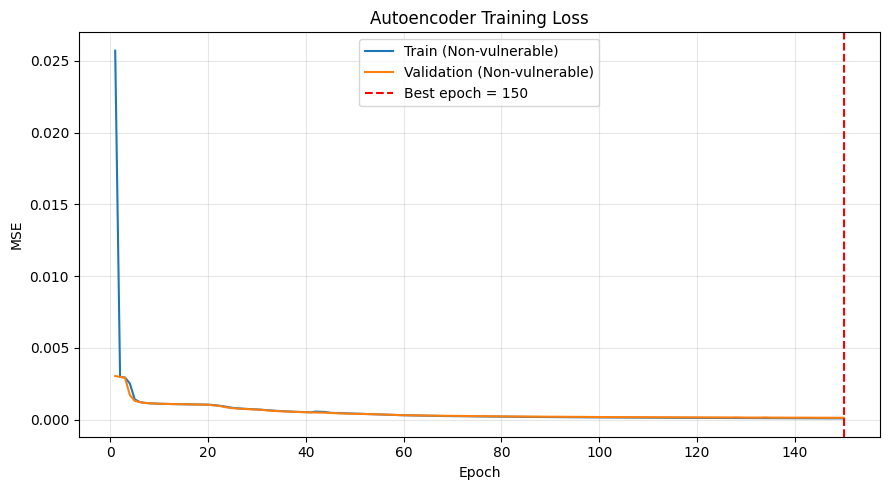

In [10]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        mode="min",
        restore_best_weights=True
    )
]

start = time.time()

history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_normal, X_val_normal),
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

training_time = time.time() - start

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))

best_epoch = int(history_df.loc[history_df["val_loss"].idxmin(), "epoch"])

print("\n========== TRAINING RESULT ==========")
print("Số epoch đã chạy:", len(history_df))
print("Epoch có val_loss thấp nhất:", best_epoch)
print("val_loss thấp nhất:", f"{history_df['val_loss'].min():.8f}")
print("Thời gian huấn luyện:", f"{training_time:.2f} giây")

if best_epoch == len(history_df):
    print("\nLƯU Ý: val_loss thấp nhất ở epoch cuối, EarlyStopping chưa kích hoạt.")
    print("Số epoch bị chặn bởi MAX_EPOCHS chứ không phải do hội tụ.")
    print("Nếu tăng MAX_EPOCHS, phải ghi nhận trong báo cáo.")

plt.figure(figsize=(9, 5))
plt.plot(history_df["epoch"], history_df["loss"], label="Train (Non-vulnerable)")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation (Non-vulnerable)")
plt.axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch = {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve,
    balanced_accuracy_score, accuracy_score,
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve
)


def reconstruction_error(model, arr, batch_size=4096):
    """MSE giữa đầu vào và đầu ra, tính riêng từng hợp đồng."""
    recon = model.predict(arr, batch_size=batch_size, verbose=0)
    return np.mean(np.square(arr - recon), axis=1).astype(np.float64)


train_errors = reconstruction_error(autoencoder, X_train)
val_errors = reconstruction_error(autoencoder, X_val)

print("========== RECONSTRUCTION ERROR THEO NHÃN ==========")

for split_name, scores, labels in [
    ("Train", train_errors, y_train_bin),
    ("Validation", val_errors, y_val_bin)
]:
    normal = scores[labels == 0]
    vulnerable = scores[labels == 1]

    print(f"\n{split_name}")
    print(f"  Non-vulnerable: n={len(normal):,} | mean={normal.mean():.8f} "
          f"| median={np.median(normal):.8f}")
    print(f"  Vulnerable    : n={len(vulnerable):,} | mean={vulnerable.mean():.8f} "
          f"| median={np.median(vulnerable):.8f}")
    print(f"  Separation Gap: {vulnerable.mean() - normal.mean():+.8f}")
    print(f"  ROC AUC (error cao => Vulnerable): {roc_auc_score(labels, scores):.6f}")

val_gap = float(val_errors[y_val_bin == 1].mean() - val_errors[y_val_bin == 0].mean())
val_auc = float(roc_auc_score(y_val_bin, val_errors))

print("\n========== KIỂM TRA CHIỀU CỦA ĐIỂM BẤT THƯỜNG ==========")

if val_gap > 0 and val_auc > 0.5:
    print("Hợp đồng Vulnerable có error cao hơn, đúng chiều đã ấn định.")
else:
    print("*** CẢNH BÁO: chiều reconstruction error không phù hợp. ***")
    print("Không tự đảo dấu điểm số. Báo cáo vấn đề và phân tích nguyên nhân.")

========== RECONSTRUCTION ERROR THEO NHÃN ==========

Train
  Non-vulnerable: n=8,300 | mean=0.00008228 | median=0.00001782
  Vulnerable    : n=19,633 | mean=0.00245544 | median=0.00081985
  Separation Gap: +0.00237316
  ROC AUC (error cao => Vulnerable): 0.933662

Validation
  Non-vulnerable: n=1,778 | mean=0.00012459 | median=0.00001745
  Vulnerable    : n=4,208 | mean=0.00226613 | median=0.00077133
  Separation Gap: +0.00214154
  ROC AUC (error cao => Vulnerable): 0.920274

========== KIỂM TRA CHIỀU CỦA ĐIỂM BẤT THƯỜNG ==========
Hợp đồng Vulnerable có error cao hơn, đúng chiều đã ấn định.


# **CHỌN NGƯỠNG PHÂN LOẠI**

Quy tắc: `reconstruction error > ngưỡng` → dự đoán `Vulnerable`.

Ngưỡng được chọn **chỉ trên tập Validation**, tối đa hóa Balanced Accuracy, rồi **cố định**
trước khi chạm vào tập Test.

========== NGƯỠNG ĐÃ CỐ ĐỊNH ==========
Tiêu chí: tối đa Balanced Accuracy trên Validation
Ngưỡng: 0.0000629042
Ngưỡng tham chiếu P95 của Non-vulnerable Train: 0.0003584791
Chiều: error > ngưỡng => Vulnerable

========== VALIDATION EVALUATION ==========
Balanced Accuracy: 0.8398
Accuracy: 0.8796
ROC AUC: 0.9203
PR AUC: 0.9593

========== CLASSIFICATION REPORT ==========
                precision    recall  f1-score   support

Non-vulnerable     0.8343    0.7418    0.7854      1778
    Vulnerable     0.8958    0.9377    0.9163      4208

      accuracy                         0.8796      5986
     macro avg     0.8650    0.8398    0.8508      5986
  weighted avg     0.8775    0.8796    0.8774      5986



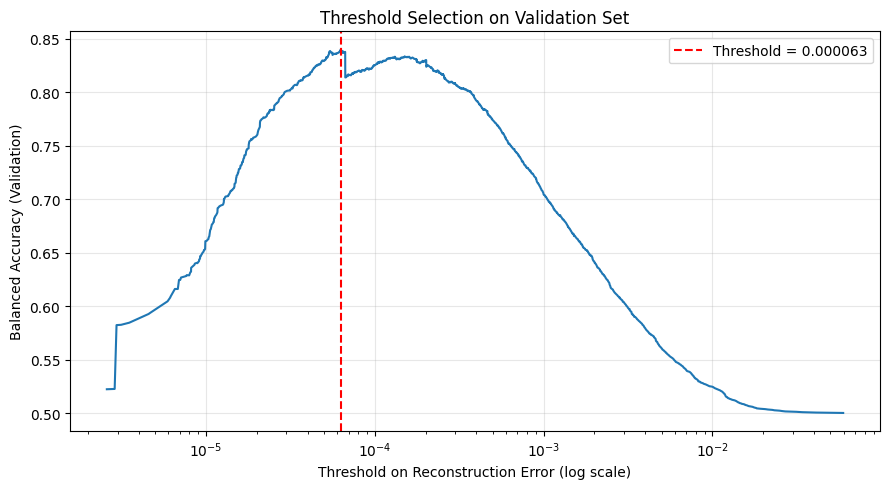

In [12]:
candidates = np.unique(np.quantile(val_errors, np.linspace(0.0005, 0.9995, 1999)))

ba_scores = np.array([
    balanced_accuracy_score(y_val_bin, (val_errors > t).astype(int))
    for t in candidates
])

THRESHOLD = float(candidates[ba_scores.argmax()])

# Ngưỡng tham chiếu, không dùng nhãn Validation
THRESHOLD_P95 = float(np.quantile(train_errors[y_train_bin == 0], 0.95))

y_val_pred = (val_errors > THRESHOLD).astype(int)

print("========== NGƯỠNG ĐÃ CỐ ĐỊNH ==========")
print("Tiêu chí: tối đa Balanced Accuracy trên Validation")
print("Ngưỡng:", f"{THRESHOLD:.10f}")
print("Ngưỡng tham chiếu P95 của Non-vulnerable Train:", f"{THRESHOLD_P95:.10f}")
print("Chiều: error > ngưỡng => Vulnerable")

print("\n========== VALIDATION EVALUATION ==========")
print("Balanced Accuracy:", round(balanced_accuracy_score(y_val_bin, y_val_pred), 4))
print("Accuracy:", round(accuracy_score(y_val_bin, y_val_pred), 4))
print("ROC AUC:", round(roc_auc_score(y_val_bin, val_errors), 4))
print("PR AUC:", round(average_precision_score(y_val_bin, val_errors), 4))

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_val_bin, y_val_pred,
    labels=[0, 1],
    target_names=["Non-vulnerable", "Vulnerable"],
    digits=4, zero_division=0
))

plt.figure(figsize=(9, 5))
plt.plot(candidates, ba_scores, linewidth=1.5)
plt.axvline(THRESHOLD, color="red", linestyle="--",
            label=f"Threshold = {THRESHOLD:.6f}")
plt.xscale("log")
plt.xlabel("Threshold on Reconstruction Error (log scale)")
plt.ylabel("Balanced Accuracy (Validation)")
plt.title("Threshold Selection on Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# FREEZE: không thay đổi THRESHOLD sau khi xem kết quả Test.

# **TESTING**

Kiến trúc, tiền xử lý, số epoch và ngưỡng đều đã cố định. Tập Test được dùng **một lần
duy nhất** từ đây.

In [13]:
def evaluation_row(split, y_true, scores, threshold, seconds=None):
    """Bảng chỉ số tại một ngưỡng cố định."""
    pred = (scores > threshold).astype(int)
    return {
        "split": split,
        "n": len(y_true),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "accuracy": accuracy_score(y_true, pred),
        "macro_precision": precision_score(y_true, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": average_precision_score(y_true, scores),
        "score_seconds": seconds
    }


start = time.time()
test_errors = reconstruction_error(autoencoder, X_test)
test_score_time = time.time() - start

y_test_pred = (test_errors > THRESHOLD).astype(int)

results_df = pd.DataFrame([
    evaluation_row("Train", y_train_bin, train_errors, THRESHOLD),
    evaluation_row("Validation", y_val_bin, val_errors, THRESHOLD),
    evaluation_row("Test", y_test_bin, test_errors, THRESHOLD, test_score_time)
])

print("========== TEST EVALUATION ==========")
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test_bin, y_test_pred), 4))
print("Accuracy:", round(accuracy_score(y_test_bin, y_test_pred), 4))
print("ROC AUC:", round(roc_auc_score(y_test_bin, test_errors), 4))
print("PR AUC:", round(average_precision_score(y_test_bin, test_errors), 4))

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test_bin, y_test_pred,
    labels=[0, 1],
    target_names=["Non-vulnerable", "Vulnerable"],
    digits=4, zero_division=0
))

print("\n========== BẢNG CHỈ SỐ ĐẦY ĐỦ ==========")
print(results_df.round(6).to_string(index=False))

print("\nThời gian huấn luyện:", f"{training_time:.2f} giây")
print("Thời gian tính error trên Test:", f"{test_score_time:.2f} giây")

========== TEST EVALUATION ==========
Balanced Accuracy: 0.847
Accuracy: 0.8852
ROC AUC: 0.9291
PR AUC: 0.9634

========== CLASSIFICATION REPORT ==========
                precision    recall  f1-score   support

Non-vulnerable     0.8443    0.7527    0.7958      1779
    Vulnerable     0.9000    0.9413    0.9202      4207

      accuracy                         0.8852      5986
     macro avg     0.8721    0.8470    0.8580      5986
  weighted avg     0.8834    0.8852    0.8832      5986


========== BẢNG CHỈ SỐ ĐẦY ĐỦ ==========
     split     n  balanced_accuracy  accuracy  macro_precision  macro_recall  macro_f1  roc_auc   pr_auc  score_seconds
     Train 27933           0.845203  0.883829         0.870376      0.845203  0.856233 0.933662 0.969167            NaN
Validation  5986           0.839791  0.879552         0.865041      0.839791  0.850821 0.920274 0.959294            NaN
      Test  5986           0.846979  0.885232         0.872131      0.846979  0.858010 0.929101 0.96337

========== CONFUSION MATRIX (%) ==========

Non-vulnerable thực tế:
  dự đoán đúng Non-vulnerable: 75.27%
  dự đoán sai thành Vulnerable: 24.73%

Vulnerable thực tế:
  dự đoán sai thành Non-vulnerable: 5.87%
  dự đoán đúng Vulnerable: 94.13%


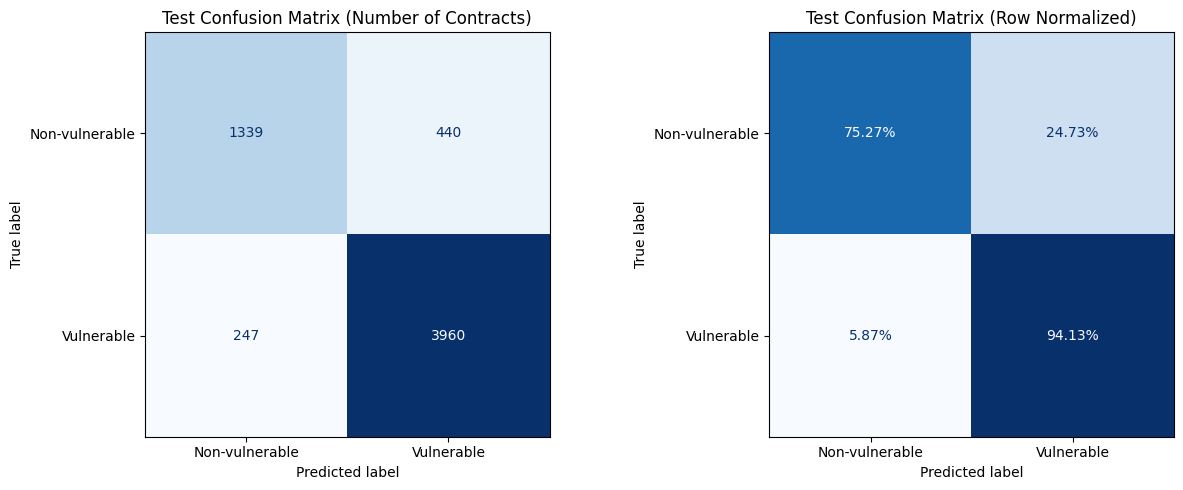

In [14]:
cm = confusion_matrix(y_test_bin, y_test_pred, labels=[0, 1])
cm_percent = confusion_matrix(y_test_bin, y_test_pred, labels=[0, 1], normalize="true")

print("========== CONFUSION MATRIX (%) ==========")

print("\nNon-vulnerable thực tế:")
print("  dự đoán đúng Non-vulnerable:", f"{cm_percent[0, 0] * 100:.2f}%")
print("  dự đoán sai thành Vulnerable:", f"{cm_percent[0, 1] * 100:.2f}%")

print("\nVulnerable thực tế:")
print("  dự đoán sai thành Non-vulnerable:", f"{cm_percent[1, 0] * 100:.2f}%")
print("  dự đoán đúng Vulnerable:", f"{cm_percent[1, 1] * 100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-vulnerable", "Vulnerable"]
).plot(cmap="Blues", values_format="d", ax=axes[0], colorbar=False)

axes[0].set_title("Test Confusion Matrix (Number of Contracts)")

ConfusionMatrixDisplay(
    confusion_matrix=cm_percent,
    display_labels=["Non-vulnerable", "Vulnerable"]
).plot(cmap="Blues", values_format=".2%", ax=axes[1], colorbar=False)

axes[1].set_title("Test Confusion Matrix (Row Normalized)")

plt.tight_layout()
plt.show()

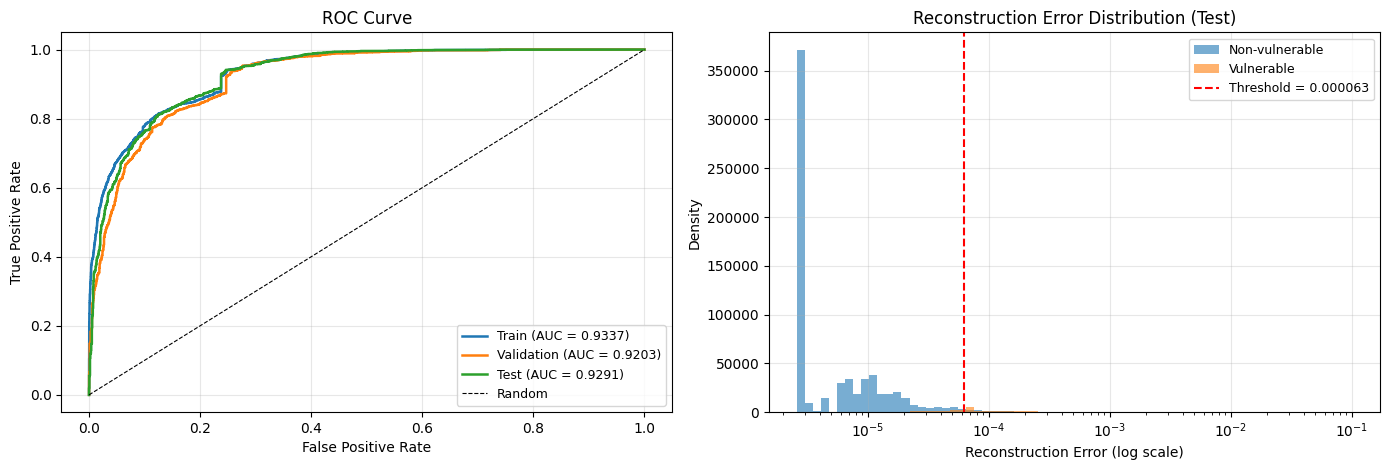

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# ROC curve
for name, labels, scores in [
    ("Train", y_train_bin, train_errors),
    ("Validation", y_val_bin, val_errors),
    ("Test", y_test_bin, test_errors)
]:
    fpr, tpr, _ = roc_curve(labels, scores)
    axes[0].plot(fpr, tpr, linewidth=1.8,
                 label=f"{name} (AUC = {roc_auc_score(labels, scores):.4f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Random")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(alpha=0.3)

# Phan phoi error tren Test
bins = np.logspace(
    np.log10(max(test_errors.min(), 1e-10)),
    np.log10(test_errors.max()),
    70
)

axes[1].hist(test_errors[y_test_bin == 0], bins=bins, alpha=0.6,
             density=True, label="Non-vulnerable")
axes[1].hist(test_errors[y_test_bin == 1], bins=bins, alpha=0.6,
             density=True, label="Vulnerable")
axes[1].axvline(THRESHOLD, color="red", linestyle="--",
                label=f"Threshold = {THRESHOLD:.6f}")
axes[1].set_xscale("log")
axes[1].set_xlabel("Reconstruction Error (log scale)")
axes[1].set_ylabel("Density")
axes[1].set_title("Reconstruction Error Distribution (Test)")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()